### Step-1: Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


### Step-2: Loading Dataset

In [2]:
df = pd.read_csv("Sentiment dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (732, 15)


,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


### Step-3: Describing dataset and checking missing values

In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nNumber of distinct raw sentiment labels:", df["Sentiment"].str.strip().nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB

Missing values per column:
 Unnamed: 0.1    0
Unnamed: 0      0
Text            0
Sentiment       0


### Step-4: Preprocessing Data and Mapping Labels

In [4]:
POSITIVE = ["Positive", "Joy", "Excitement", "Contentment", "Gratitude", "Serenity", "Happy", "Awe", "Hopeful", "Pride", "Elation", "Euphoria", "Enthusiasm", "Determination", "Inspiration", "Playful", "Happiness", "Hope", "Empowerment", "Inspired", "Admiration", "Calmness", "Compassion", "Tenderness", "Fulfillment", "Reverence", "Proud", "Grateful", "Compassionate", "Thrill", "Enchantment", "Love", "Amusement", "Kind", "Empathetic", "Free-spirited", "Confident", "Satisfaction", "Accomplishment", "Harmony", "Creativity", "Wonder", "Adventure", "Enjoyment", "Affection", "Adoration", "Zest", "Whimsy", "Radiance", "Rejuvenation", "Coziness", "Resilience", "Captivation", "Tranquility", "Mischievous", "Overjoyed", "Motivation", "JoyfulReunion", "Blessed", "Appreciation", "Confidence", "Wonderment", "Optimism", "PlayfulJoy", "DreamChaser", "Elegance", "Melodic", "FestiveJoy", "InnerJourney", "Freedom", "Dazzle", "Adrenaline", "ArtisticBurst", "CulinaryOdyssey", "Spark", "Marvel", "Positivity", "Kindness", "Friendship", "Success", "Amazement", "Romance", "Grandeur", "Energy", "Celebration", "Charm", "Ecstasy", "Colorful", "Hypnotic", "Connection", "Iconic", "Touched", "Triumph", "Heartwarming", "Sympathy", "Solace", "Breakthrough", "Imagination", "Vibrancy", "Mesmerizing", "Relief", "Arousal", "Joy in Baking", "Culinary Adventure", "Winter Magic", "Thrilling Journey", "Nature's Beauty", "Celestial Wonder", "Creative Inspiration", "Runway Creativity", "Ocean's Freedom", "Renewed Effort"]
NEGATIVE = ["Negative", "Despair", "Grief", "Loneliness", "Sad", "Embarrassed", "Frustration", "Regret", "Numbness", "Melancholy", "Hate", "Bad", "Disgust", "Bitterness", "Frustrated", "Betrayal", "Boredom", "Desolation", "Overwhelmed", "Bitter", "Shame", "Jealousy", "Resentment", "Fearful", "Jealous", "Devastated", "Envious", "Dismissive", "Heartbreak", "Anger", "Fear", "Sadness", "Disappointed", "Anxiety", "Intimidation", "Helplessness", "Envy", "Yearning", "Apprehensive", "Isolation", "Disappointment", "Sorrow", "Loss", "Suffering", "EmotionalStorm", "LostLove", "Exhaustion", "Darkness", "Desperation", "Ruins", "Heartache", "Solitude", "Obstacle", "Pressure", "Miscalculation"]
NEUTRAL = ["Neutral", "Curiosity", "Nostalgia", "Acceptance", "Confusion", "Indifference", "Ambivalence", "Surprise", "Anticipation", "Reflection", "Contemplation", "Exploration", "Emotion", "Mindfulness", "Pensive", "Intrigue", "Suspense", "Journey", "Engagement", "Bittersweet", "Immersion", "Challenge", "Envisioning History", "Whispers of the Past"]

label_map = {}
label_map.update({w: "Positive" for w in POSITIVE})
label_map.update({w: "Negative" for w in NEGATIVE})
label_map.update({w: "Neutral"  for w in NEUTRAL})

df["Text"] = df["Text"].str.strip()
df["Sentiment"] = df["Sentiment"].str.strip()
df["Label"] = df["Sentiment"].map(label_map)

# Any label we forgot to map would show up here
print("Unmapped labels:", df.loc[df["Label"].isna(), "Sentiment"].unique())

df = df.dropna(subset=["Label"]).drop_duplicates(subset="Text").reset_index(drop=True)
print("Rows after cleaning:", len(df))
print(df["Label"].value_counts())

Unmapped labels: []
Rows after cleaning: 706
Label
Positive    419
Negative    184
Neutral     103
Name: count, dtype: int64


### Step-5: Plotting Class Distribution

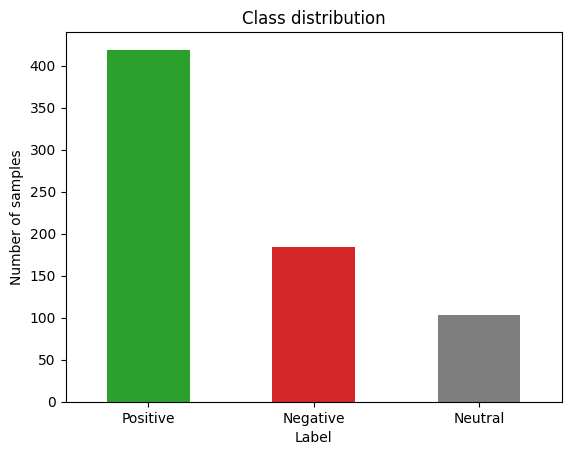

In [5]:
df["Label"].value_counts().plot(kind="bar", color=["tab:green", "tab:red", "tab:gray"])
plt.title("Class distribution")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

### Step-6: Splitting the data and Applying TF-IDF

In [6]:
class_names = ["Negative", "Neutral", "Positive"]          
class_to_id = {c: i for i, c in enumerate(class_names)}

X_text = df["Text"].str.lower()
y = df["Label"].map(class_to_id).values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=SEED
)

vectorizer = TfidfVectorizer(max_features=1500, ngram_range=(1, 2), stop_words="english")
X_train = vectorizer.fit_transform(X_train_text).toarray().astype("float32")
X_test  = vectorizer.transform(X_test_text).toarray().astype("float32")

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (564, 1500)  Test: (142, 1500)


### Step-7: Building Neural Network

In [7]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.Dropout(0.5),
    layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3)),
    layers.Dropout(0.5),
    layers.Dense(3, activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",   # integer labels 0/1/2
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         192,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 3)                   │             195 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 200,579 (783.51 KB)

 Trainable params: 200,579 (783.51 KB)

 Non-trainable params: 0 (0.00 B)

### Step-8: Training Model

In [8]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = {i: w for i, w in enumerate(weights)}
print("Class weights:", class_weight)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=8, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=[early_stop],
    verbose=1,
)

Class weights: {0: np.float64(1.2789115646258504), 1: np.float64(2.292682926829268), 2: np.float64(0.5611940298507463)}
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.3082 - loss: 1.3681 - val_accuracy: 0.2035 - val_loss: 1.3012
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4058 - loss: 1.2724 - val_accuracy: 0.4867 - val_loss: 1.2388
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5898 - loss: 1.2159 - val_accuracy: 0.5929 - val_loss: 1.1971
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7339 - loss: 1.1616 - val_accuracy: 0.6726 - val_loss: 1.1523
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8470 - loss: 1.0861 - val_accuracy: 0.7522 - val_loss: 1.0914
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8980 - loss: 0.9710 - val_accuracy: 0.7788 - val_loss: 0.9996
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9379 - loss: 0.8126 - val_accuracy: 0.8142 - v

### Step-9: Plotting Training and Validation Loss

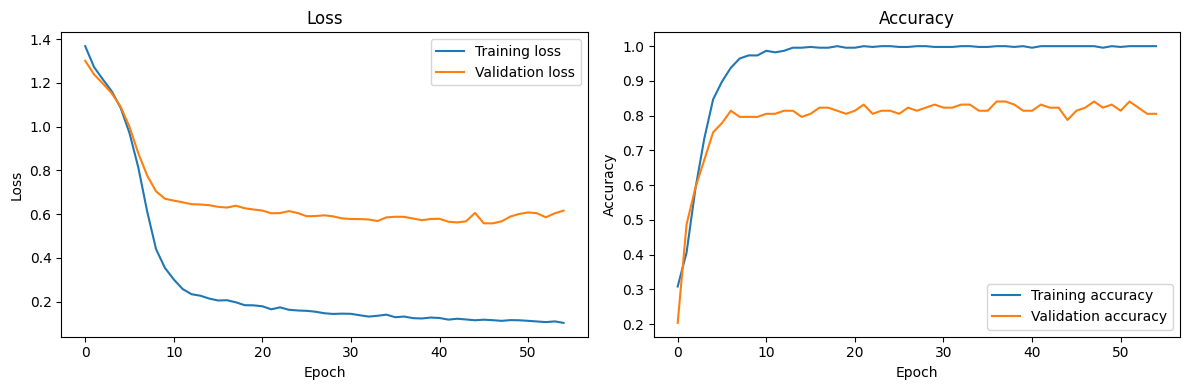

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["loss"], label="Training loss")
ax[0].plot(history.history["val_loss"], label="Validation loss")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="Training accuracy")
ax[1].plot(history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].legend()

plt.tight_layout()
plt.show()

### Step-10: Evaluating Model

Test loss    : 0.8285
Test accuracy: 0.7394

Classification report:

              precision    recall  f1-score   support

    Negative       0.71      0.73      0.72        37
     Neutral       0.50      0.38      0.43        21
    Positive       0.80      0.83      0.81        84

    accuracy                           0.74       142
   macro avg       0.67      0.65      0.66       142
weighted avg       0.73      0.74      0.73       142



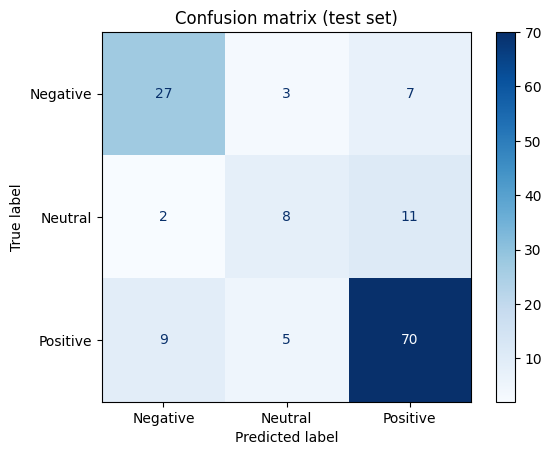

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print("\nClassification report:\n")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix (test set)")
plt.show()

### Step-11: Predicting on New Sentences

In [11]:
def predict_sentiment(text):
    vec = vectorizer.transform([text.lower()]).toarray().astype("float32")
    probs = model.predict(vec, verbose=0)[0]
    return class_names[int(np.argmax(probs))], dict(zip(class_names, probs.round(3)))

for s in ["What a wonderful, amazing day!",
          "He is a bad boy",
          "Going to the market to buy vegetables."]:
    print(s, "->", predict_sentiment(s))

What a wonderful, amazing day! -> ('Positive', {'Negative': np.float32(0.009), 'Neutral': np.float32(0.021), 'Positive': np.float32(0.97)})
He is a bad boy -> ('Negative', {'Negative': np.float32(0.995), 'Neutral': np.float32(0.002), 'Positive': np.float32(0.003)})
Going to the market to buy vegetables. -> ('Positive', {'Negative': np.float32(0.185), 'Neutral': np.float32(0.075), 'Positive': np.float32(0.74)})
